# Predicting Student Health Risk

## Project aim
This project develops and compares machine learning models to predict
student health categories: at-risk, unhealthy and fit.

## Data
The data come from the Kaggle competition Predicting Student Health Risk,
Playground Series, Season 6 Episode 7. They are synthetically generated.

## Evaluation
Models will be evaluated using balanced accuracy, which gives equal
importance to recall for each health category.

## Competition
https://www.kaggle.com/competitions/playground-series-s6e7

In [2]:
from google.colab import files

uploaded = files.upload()

Saving playground-series-s6e7.zip to playground-series-s6e7.zip


In [3]:
from pathlib import Path
import zipfile

# Locate the uploaded ZIP, including any renamed duplicate.
zip_files = [
    name for name in uploaded
    if name.lower().endswith(".zip")
]

if len(zip_files) != 1:
    raise ValueError("Please upload exactly one data ZIP file.")

zip_path = Path(zip_files[0])
data_folder = Path("/content/student_health_data")
data_folder.mkdir(parents=True, exist_ok=True)

# Extract only the three CSV files needed for this project.
required_files = {
    "train.csv",
    "test.csv",
    "sample_submission.csv"
}

with zipfile.ZipFile(zip_path) as archive:
    for filename in required_files:
        matches = [
            name for name in archive.namelist()
            if Path(name).name == filename
        ]

        if len(matches) != 1:
            raise ValueError(f"Expected exactly one {filename} in the ZIP.")

        (data_folder / filename).write_bytes(
            archive.read(matches[0])
        )

print("Data files extracted:")
for path in sorted(data_folder.glob("*.csv")):
    print(path.name)

Data files extracted:
sample_submission.csv
test.csv
train.csv


In [4]:
import pandas as pd

train = pd.read_csv(data_folder / "train.csv")
test = pd.read_csv(data_folder / "test.csv")
sample_submission = pd.read_csv(
    data_folder / "sample_submission.csv"
)

print("Training data:", train.shape)
print("Test data:", test.shape)
print("Submission template:", sample_submission.shape)

display(train.head())

Training data: (690088, 15)
Test data: (295753, 14)
Submission template: (295753, 2)


,id,health_condition,sleep_duration,heart_rate,bmi,calorie_expenditure,step_count,exercise_duration,water_intake,diet_type,stress_level,sleep_quality,physical_activity_level,smoking_alcohol,gender
0,0,unhealthy,5.22,70.6,25.66,2174.0,1326.0,19.8,1.86,veg,high,average,sedentary,yes,female
1,1,at-risk,5.53,71.3,25.84,1966.0,9891.0,49.9,1.26,non-veg,low,average,moderate,yes,other
2,2,unhealthy,5.29,75.4,24.54,2688.0,14216.0,38.1,1.60,veg,high,poor,active,yes,male
3,3,unhealthy,4.70,77.2,23.13,2630.0,7174.0,59.9,2.02,veg,high,average,active,occasional,female
4,4,at-risk,7.23,73.4,28.44,2560.0,6584.0,46.0,2.25,veg,NaN,average,sedentary,NaN,male


In [5]:
target = "health_condition"

# Check that the expected target and predictor columns are present.
assert target in train.columns
assert target not in test.columns
assert train["id"].is_unique
assert test["id"].is_unique
assert train[target].notna().all()

assert set(train.columns) - {target} == set(test.columns)
assert sample_submission["id"].equals(test["id"])

# Separate predictors by their current data types.
predictor_columns = [
    column for column in train.columns
    if column not in ["id", target]
]

numeric_columns = (
    train[predictor_columns]
    .select_dtypes(include="number")
    .columns
    .tolist()
)

categorical_columns = (
    train[predictor_columns]
    .select_dtypes(exclude="number")
    .columns
    .tolist()
)

print("Number of predictors:", len(predictor_columns))
print("\nNumeric predictors:", numeric_columns)
print("\nCategorical predictors:", categorical_columns)
print("\nBasic structure checks passed.")

Number of predictors: 13

Numeric predictors: ['sleep_duration', 'heart_rate', 'bmi', 'calorie_expenditure', 'step_count', 'exercise_duration', 'water_intake']

Categorical predictors: ['diet_type', 'stress_level', 'sleep_quality', 'physical_activity_level', 'smoking_alcohol', 'gender']

Basic structure checks passed.


In [6]:
target_summary = (
    train[target]
    .value_counts()
    .rename_axis("health_condition")
    .reset_index(name="count")
)

target_summary["percentage"] = (
    target_summary["count"] / len(train) * 100
).round(2)

display(target_summary)

,health_condition,count,percentage
0,at-risk,592561,85.87
1,unhealthy,57724,8.36
2,fit,39803,5.77


## Target distribution

The training dataset contains 690,088 records. The at-risk category
accounts for 85.87% of records, followed by unhealthy at 8.36% and
fit at 5.77%.

The target is strongly imbalanced. A model predicting at-risk for every
record would achieve 85.87% ordinary accuracy but only 33.33% balanced
accuracy. Therefore, balanced accuracy is used to assess how well
models recognise all three categories.

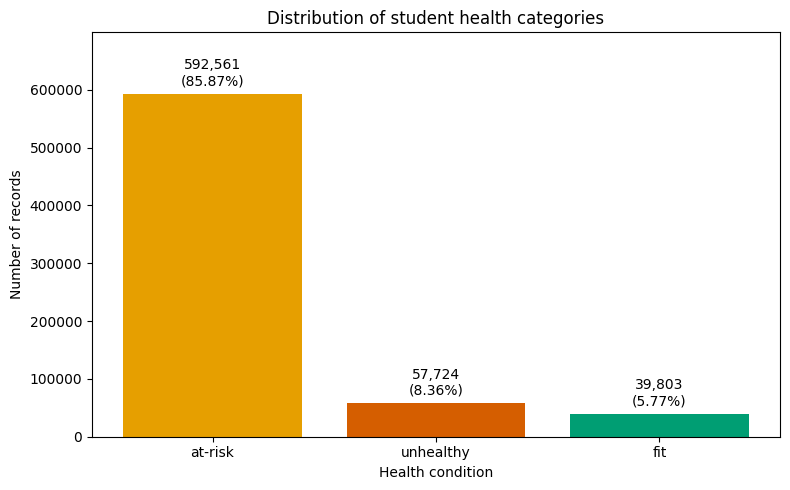

In [7]:
import matplotlib.pyplot as plt

class_order = ["at-risk", "unhealthy", "fit"]
class_counts = train[target].value_counts().reindex(class_order)

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    class_counts.index,
    class_counts.values,
    color=["#E69F00", "#D55E00", "#009E73"]
)

ax.bar_label(
    bars,
    labels=[
        f"{count:,}\n({count / len(train):.2%})"
        for count in class_counts
    ],
    padding=4
)

ax.set_title("Distribution of student health categories")
ax.set_xlabel("Health condition")
ax.set_ylabel("Number of records")
ax.set_ylim(0, class_counts.max() * 1.18)

plt.tight_layout()
plt.show()

In [8]:
missing_summary = pd.DataFrame({
    "train_missing_count": train[predictor_columns].isna().sum(),
    "train_missing_percent": (
        train[predictor_columns].isna().mean() * 100
    ),
    "test_missing_count": test[predictor_columns].isna().sum(),
    "test_missing_percent": (
        test[predictor_columns].isna().mean() * 100
    )
})

missing_summary = missing_summary.sort_values(
    "train_missing_percent",
    ascending=False
)

display(missing_summary.round(2))

,train_missing_count,train_missing_percent,test_missing_count,test_missing_percent
stress_level,82811,12.00,35490,12.00
sleep_duration,75999,11.01,32571,11.01
sleep_quality,58331,8.45,24999,8.45
calorie_expenditure,52853,7.66,22652,7.66
water_intake,43477,6.30,18633,6.30
physical_activity_level,36621,5.31,15695,5.31
smoking_alcohol,28582,4.14,12249,4.14
gender,21373,3.10,9160,3.10
step_count,13916,2.02,5964,2.02
bmi,13898,2.01,5956,2.01


In [9]:
print("SUMMARY OF NUMERIC FEATURES")
display(train[numeric_columns].describe().T.round(2))

print("\nCATEGORIES AND COUNTS")

for column in categorical_columns:
    print(f"\n{column}")
    display(
        train[column]
        .value_counts(dropna=False)
        .rename("count")
        .to_frame()
    )

duplicate_count = train.duplicated(
    subset=predictor_columns + [target]
).sum()

print(
    "\nRepeated rows with identical predictors and target "
    f"(excluding id): {duplicate_count:,}"
)

SUMMARY OF NUMERIC FEATURES


,count,mean,std,min,25%,50%,75%,max
sleep_duration,614089.0,6.99,1.22,3.0,6.16,6.99,7.81,10.00
heart_rate,682255.0,75.10,8.18,50.0,69.40,75.10,80.70,107.70
bmi,676190.0,22.98,2.48,16.0,21.32,22.99,24.66,34.82
calorie_expenditure,637235.0,2226.08,347.53,1200.0,2053.00,2241.00,2456.00,3580.00
step_count,676172.0,8615.95,3929.40,1002.0,5389.00,8856.00,12114.00,14999.00
exercise_duration,683187.0,38.75,14.74,0.0,29.20,39.40,49.40,99.80
water_intake,646611.0,2.19,0.52,0.5,1.84,2.17,2.50,4.72



CATEGORIES AND COUNTS

diet_type


,count
diet_type,
veg,231432
balanced,226888
non-veg,224867
NaN,6901



stress_level


,count
stress_level,
medium,261819
high,177750
low,167708
NaN,82811


... (5 outputs left out)

,count
smoking_alcohol,
yes,223730
no,219791
occasional,217985
NaN,28582



gender


,count
gender,
male,237756
female,224016
other,206943
NaN,21373



Repeated rows with identical predictors and target (excluding id): 0


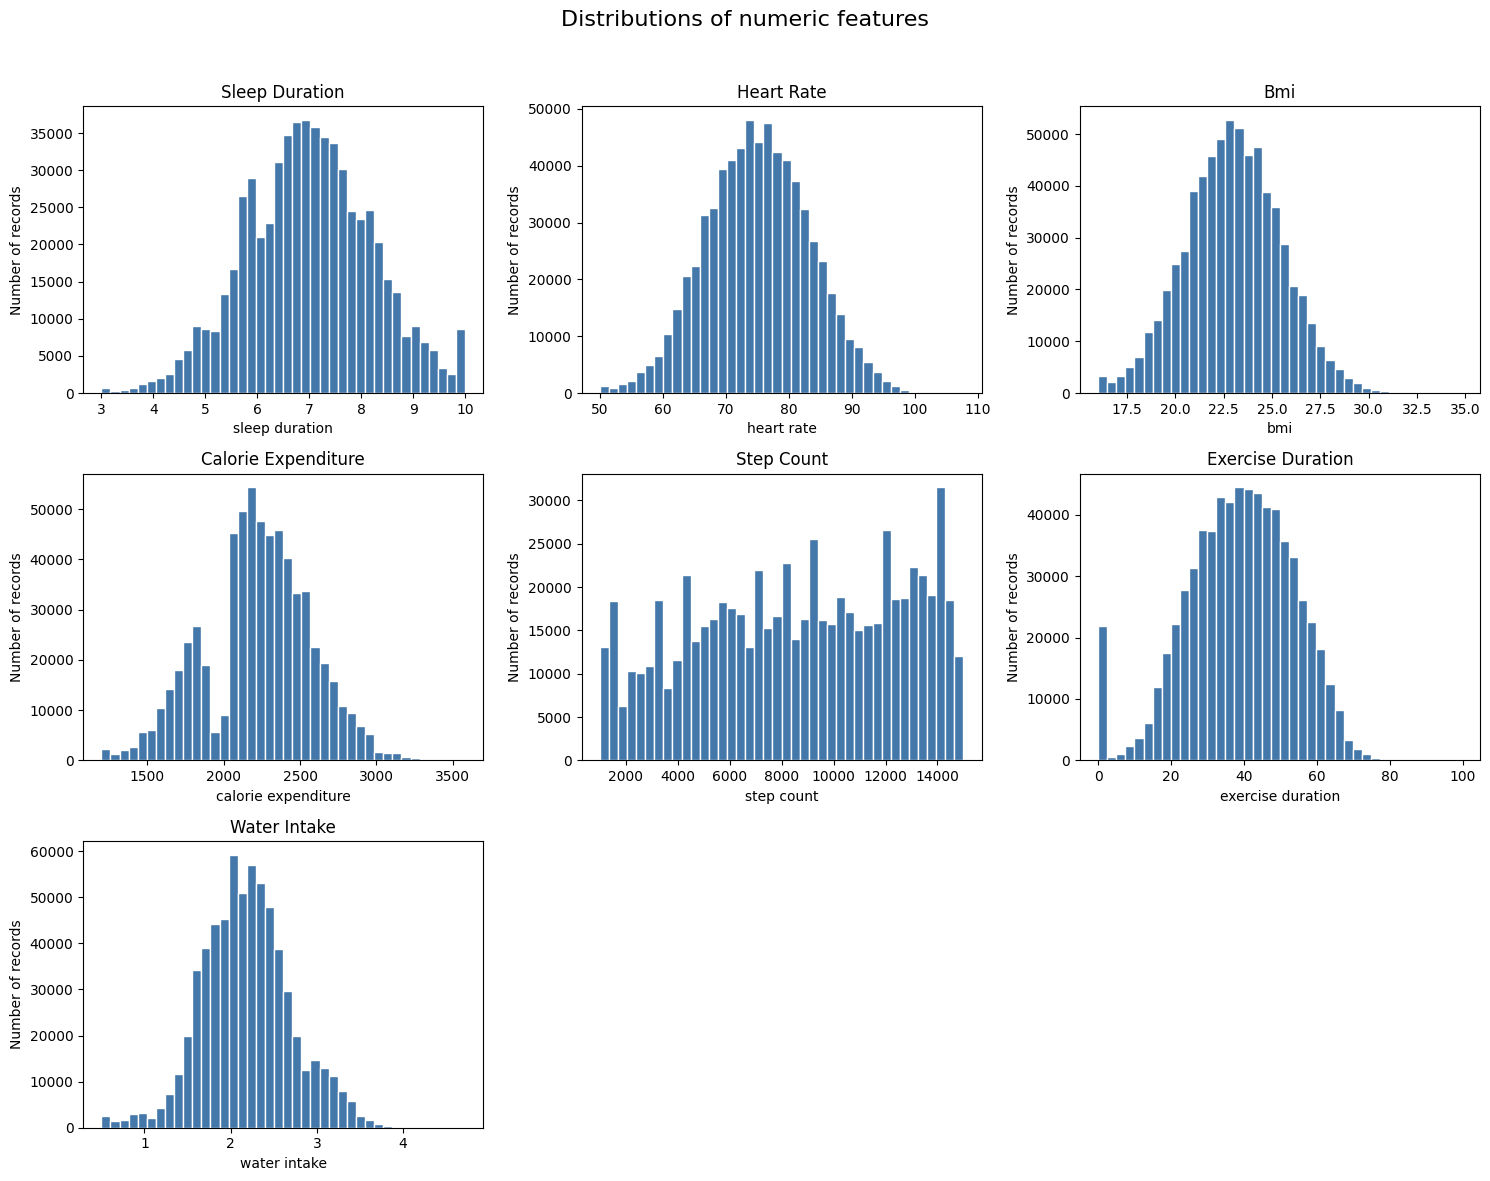

In [10]:
import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.ravel()

for ax, column in zip(axes, numeric_columns):
    ax.hist(
        train[column].dropna(),
        bins=40,
        color="#4477AA",
        edgecolor="white"
    )

    ax.set_title(column.replace("_", " ").title())
    ax.set_xlabel(column.replace("_", " "))
    ax.set_ylabel("Number of records")

# Hide unused panels.
for ax in axes[len(numeric_columns):]:
    ax.set_visible(False)

fig.suptitle("Distributions of numeric features", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

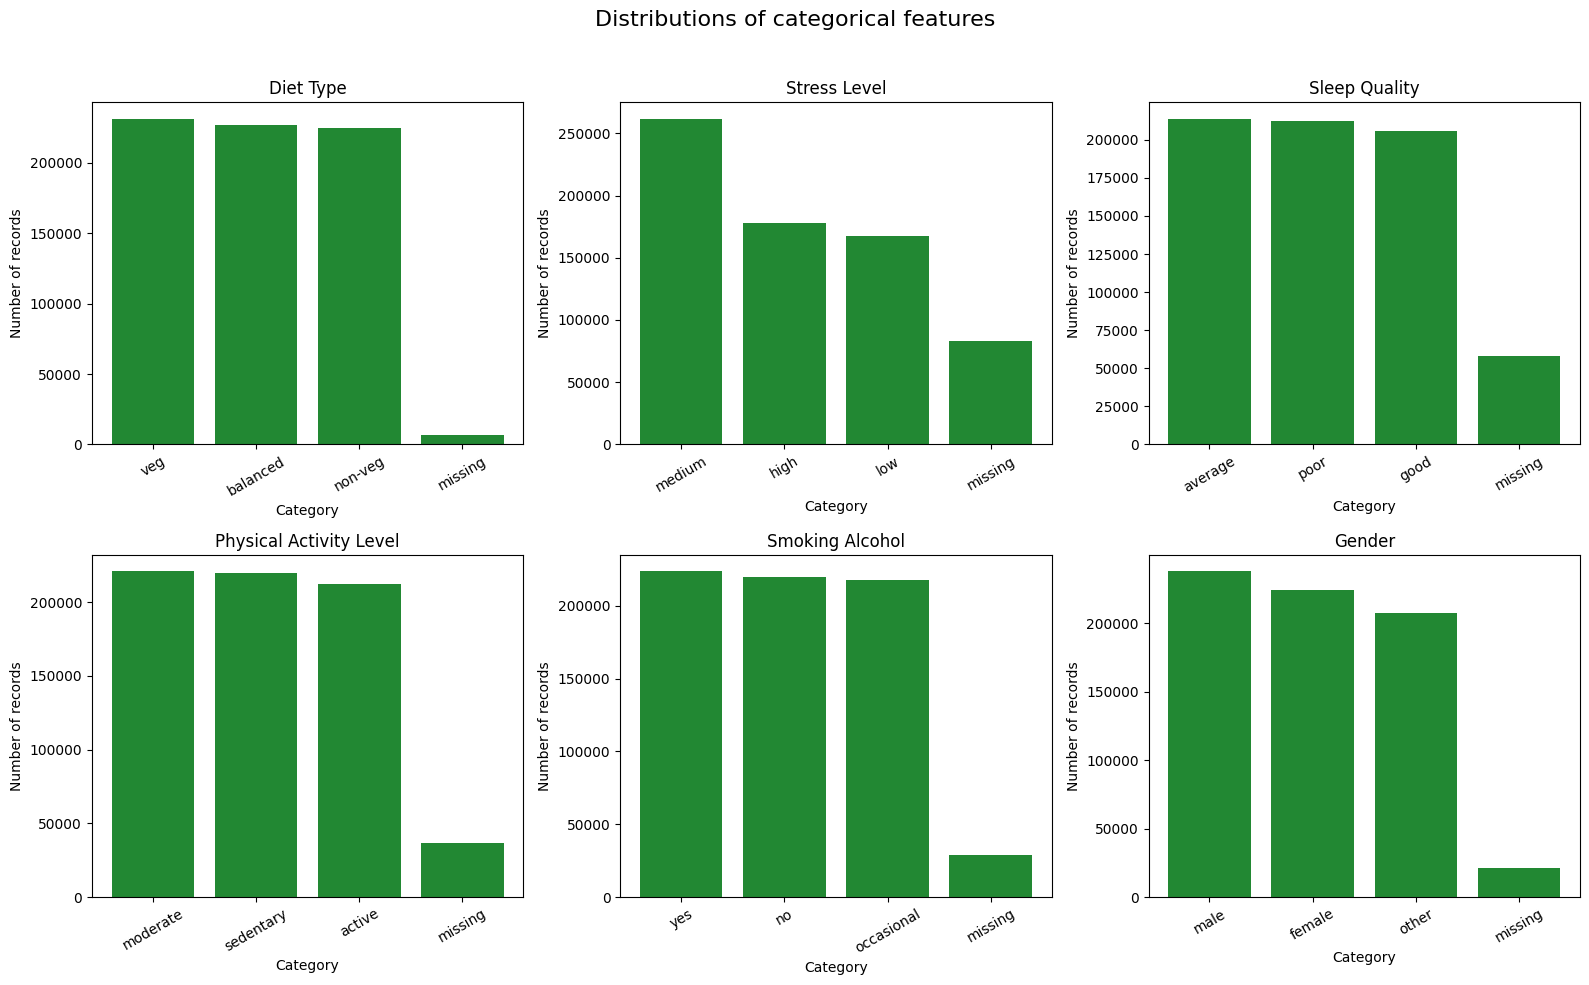

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

for ax, column in zip(axes.ravel(), categorical_columns):
    counts = (
        train[column]
        .fillna("missing")
        .value_counts()
    )

    ax.bar(
        counts.index.astype(str),
        counts.values,
        color="#228833"
    )

    ax.set_title(column.replace("_", " ").title())
    ax.set_xlabel("Category")
    ax.set_ylabel("Number of records")
    ax.tick_params(axis="x", rotation=30)

fig.suptitle("Distributions of categorical features", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

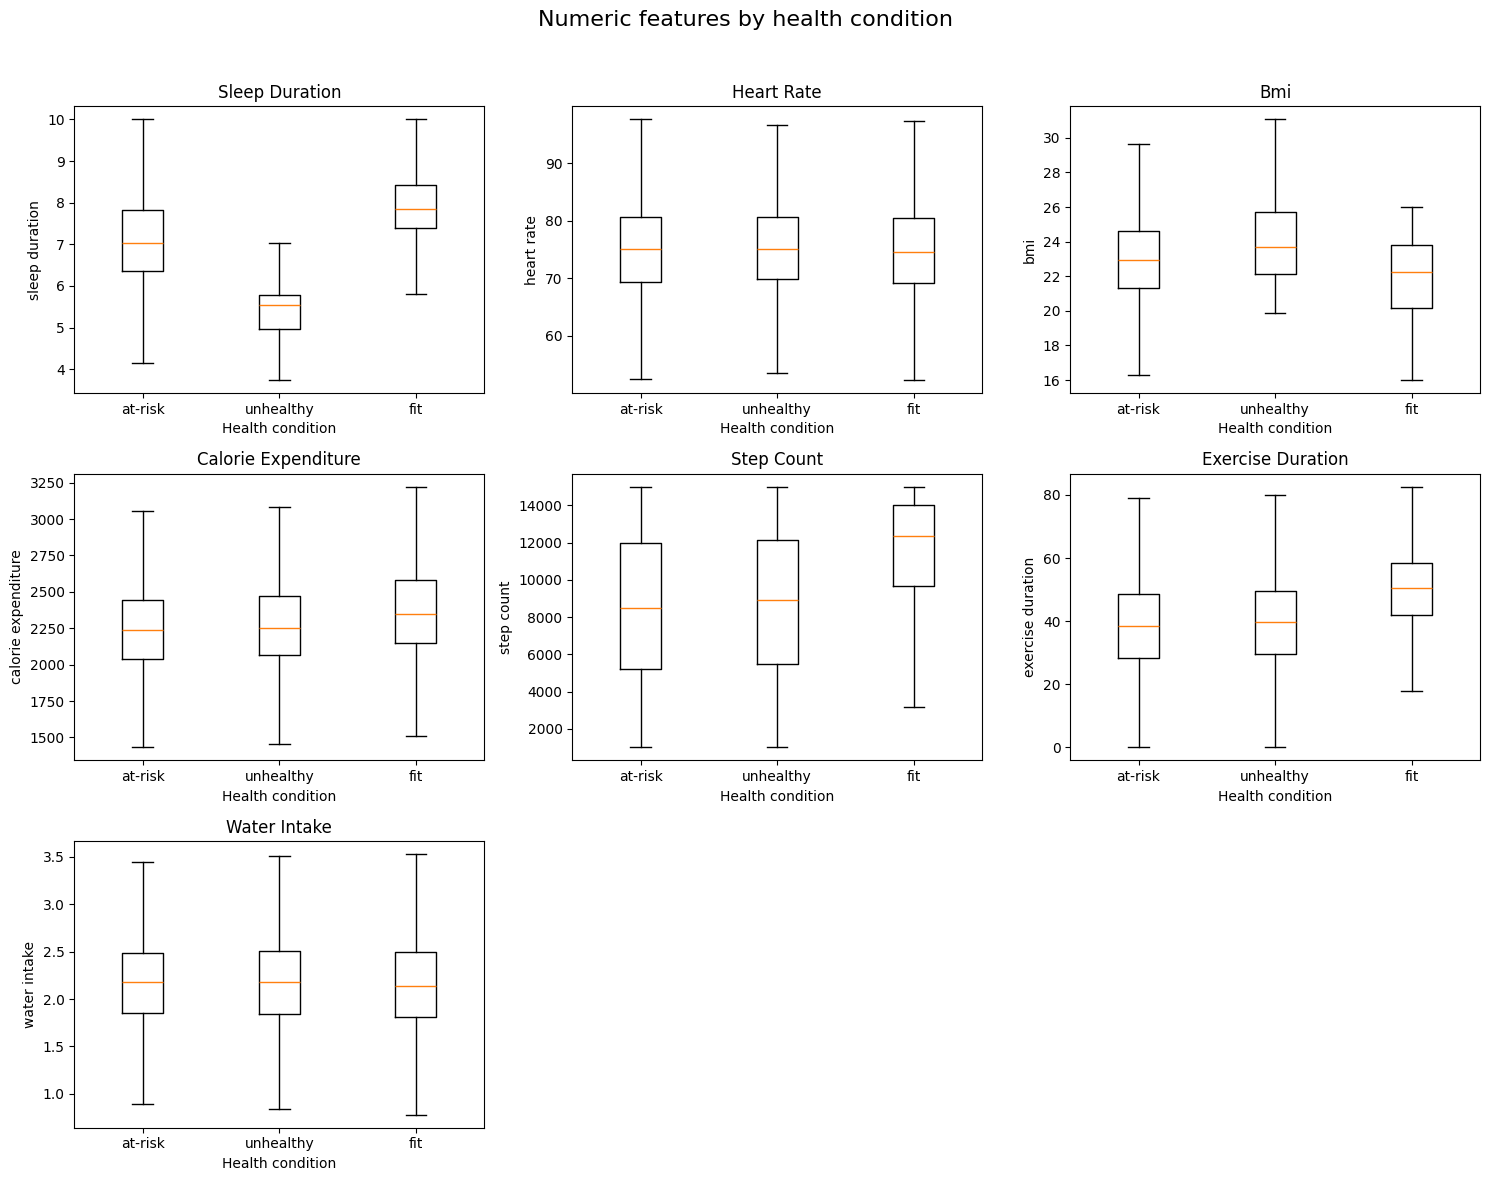

Extreme points are hidden for readability; no observations have been removed.


In [12]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.ravel()

for ax, column in zip(axes, numeric_columns):
    values_by_class = [
        train.loc[train[target] == label, column]
        .dropna()
        .to_numpy()
        for label in class_order
    ]

    ax.boxplot(
        values_by_class,
        tick_labels=class_order,
        showfliers=False
    )

    ax.set_title(column.replace("_", " ").title())
    ax.set_xlabel("Health condition")
    ax.set_ylabel(column.replace("_", " "))

for ax in axes[len(numeric_columns):]:
    ax.set_visible(False)

fig.suptitle(
    "Numeric features by health condition",
    fontsize=16
)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

print(
    "Extreme points are hidden for readability; "
    "no observations have been removed."
)

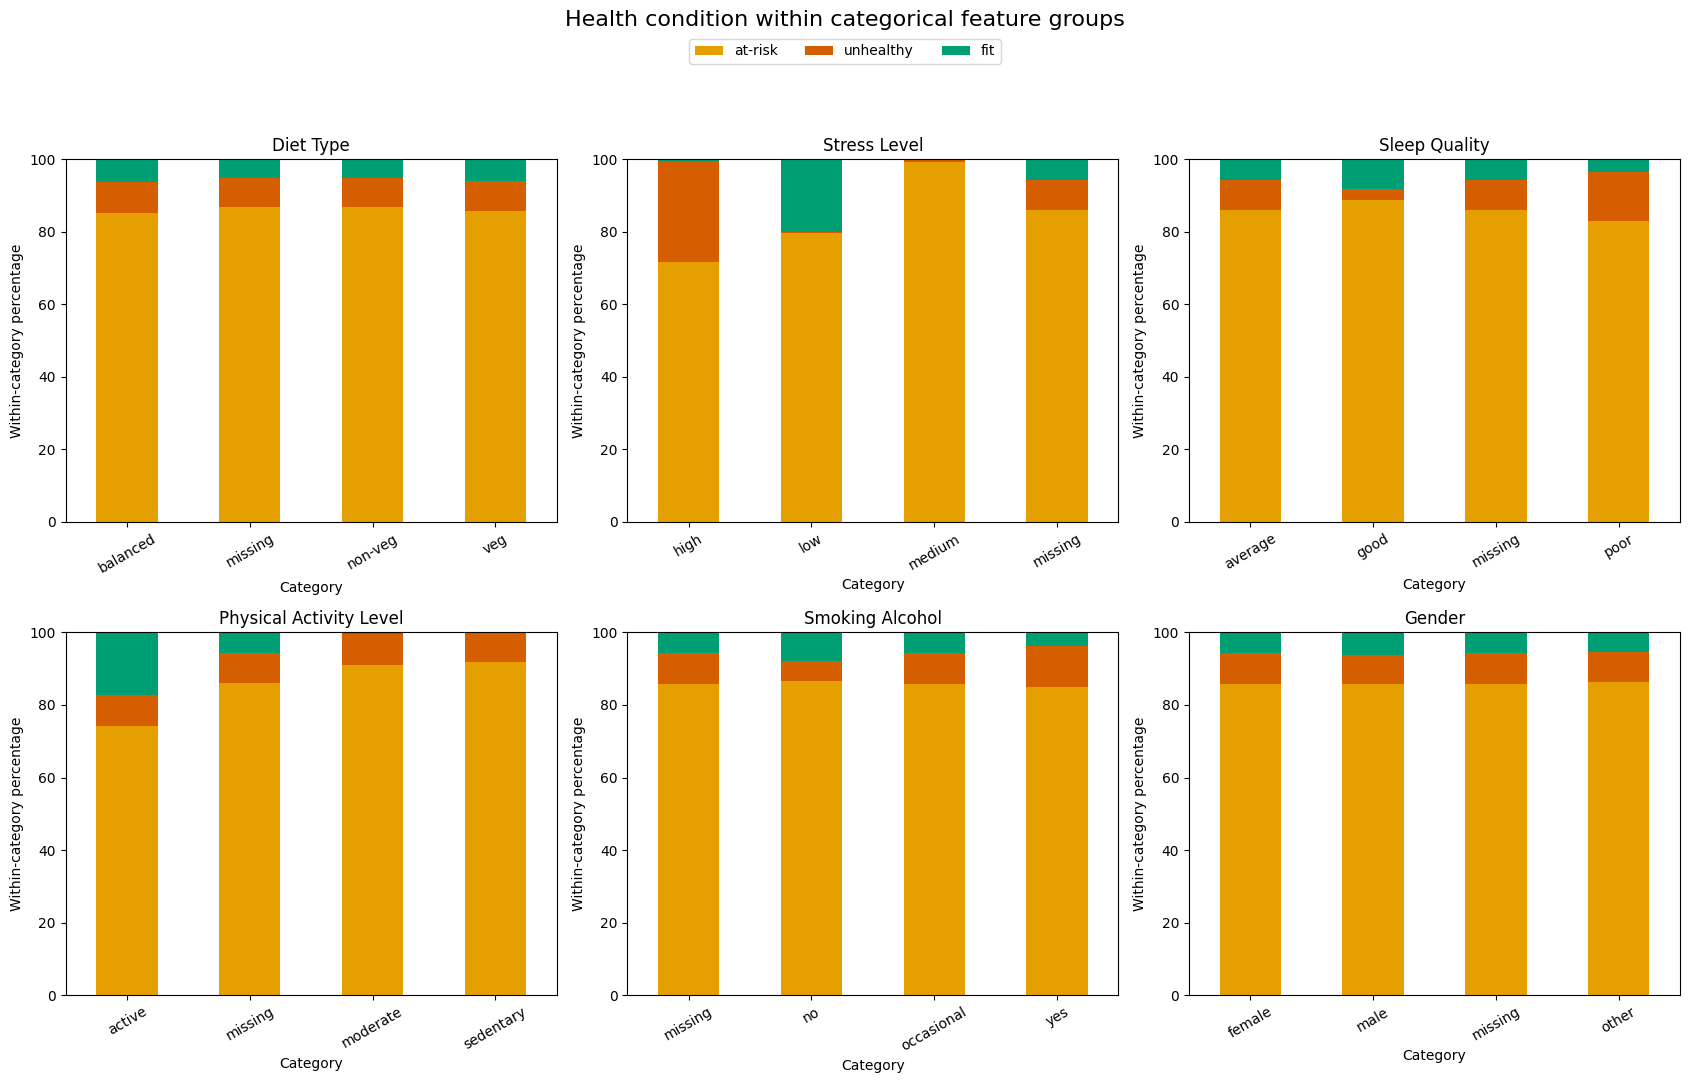

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(17, 11))

for ax, column in zip(axes.ravel(), categorical_columns):
    category_labels = train[column].fillna("missing")

    proportions = pd.crosstab(
        category_labels,
        train[target],
        normalize="index"
    ).reindex(columns=class_order, fill_value=0) * 100

    proportions.plot(
        kind="bar",
        stacked=True,
        ax=ax,
        color=["#E69F00", "#D55E00", "#009E73"],
        legend=False
    )

    ax.set_title(column.replace("_", " ").title())
    ax.set_xlabel("Category")
    ax.set_ylabel("Within-category percentage")
    ax.set_ylim(0, 100)
    ax.tick_params(axis="x", rotation=30)

handles, labels = axes.ravel()[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.96),
    ncol=3
)

fig.suptitle(
    "Health condition within categorical feature groups",
    fontsize=16
)

plt.tight_layout(rect=[0, 0, 1, 0.91])
plt.show()

## Main exploratory findings

1. The target is strongly imbalanced: 85.87% of records are at-risk,
   8.36% are unhealthy and 5.77% are fit. Balanced accuracy is therefore
   important for evaluating recognition of all three classes.

2. Sleep duration differs noticeably across health categories.
   The unhealthy group has a lower median sleep duration, while the
   fit group has a higher median.

3. Stress level shows a strong association with the target.
   High-stress records have a larger unhealthy proportion, while
   low-stress records have a larger fit proportion. The medium-stress
   group is almost entirely at-risk.

4. Fit records generally have higher step counts and longer exercise
   duration. The active physical-activity category also has a larger
   fit proportion than the moderate and sedentary categories.

5. BMI is generally higher in the unhealthy group and lower in the fit
   group, although the distributions overlap.

6. Heart rate and water intake have similar distributions across the
   target classes. Diet type and gender also show relatively small
   differences in class proportions. Their predictive contribution
   will need to be assessed through modelling.

7. Several numeric distributions are roughly bell-shaped, but some
   show spikes or irregularities. Examples include zero exercise
   duration and sleep duration near the upper boundary. These are
   retained because the plots alone do not establish data errors.

8. Missing values occur in every predictor. No repeated rows with
   identical predictors and target were found.

These findings describe associations in a synthetic dataset.
They do not establish causal effects or clinical rules.

In [14]:
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

X = train[predictor_columns].copy()
y = train[target].copy()

X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Training portion:", X_train.shape)
print("Validation portion:", X_valid.shape)

split_distribution = pd.DataFrame({
    "training_percent": (
        y_train.value_counts(normalize=True) * 100
    ),
    "validation_percent": (
        y_valid.value_counts(normalize=True) * 100
    )
}).reindex(class_order)

display(split_distribution.round(2))

Training portion: (552070, 13)
Validation portion: (138018, 13)


,training_percent,validation_percent
health_condition,,
at-risk,85.87,85.87
unhealthy,8.36,8.36
fit,5.77,5.77


In [15]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score
)

baseline = DummyClassifier(strategy="most_frequent")

baseline.fit(X_train, y_train)
baseline_predictions = baseline.predict(X_valid)

baseline_accuracy = accuracy_score(
    y_valid,
    baseline_predictions
)

baseline_balanced_accuracy = balanced_accuracy_score(
    y_valid,
    baseline_predictions
)

results = [{
    "model": "Most frequent class baseline",
    "accuracy": baseline_accuracy,
    "balanced_accuracy": baseline_balanced_accuracy
}]

display(pd.DataFrame(results).round(4))

,model,accuracy,balanced_accuracy
0,Most frequent class baseline,0.8587,0.3333


In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

numeric_preprocessing = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="median",
            add_indicator=True
        )
    ),
    ("scaler", StandardScaler())
])

categorical_preprocessing = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="constant",
            fill_value="missing"
        )
    ),
    (
        "encoder",
        OneHotEncoder(handle_unknown="ignore")
    )
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_preprocessing, numeric_columns),
    (
        "categorical",
        categorical_preprocessing,
        categorical_columns
    )
])

logistic_model = Pipeline([
    ("preprocessing", preprocessor),
    (
        "classifier",
        LogisticRegression(
            class_weight="balanced",
            solver="lbfgs",
            max_iter=1000,
            random_state=RANDOM_STATE
        )
    )
])

print("Preprocessing and logistic regression pipeline created.")

Preprocessing and logistic regression pipeline created.


In [17]:
import time
from sklearn.metrics import classification_report

start_time = time.perf_counter()

# All learned preprocessing is fitted using X_train only.
logistic_model.fit(X_train, y_train)

logistic_predictions = logistic_model.predict(X_valid)

elapsed_seconds = time.perf_counter() - start_time

logistic_result = {
    "model": "Balanced logistic regression",
    "accuracy": accuracy_score(
        y_valid,
        logistic_predictions
    ),
    "balanced_accuracy": balanced_accuracy_score(
        y_valid,
        logistic_predictions
    )
}

# Replace any previous result if this cell is run again.
results = [
    result for result in results
    if result["model"] != logistic_result["model"]
]
results.append(logistic_result)

display(
    pd.DataFrame(results)
    .sort_values("balanced_accuracy", ascending=False)
    .round(4)
)

print(f"\nTraining and prediction time: {elapsed_seconds:.1f} seconds")

print("\nPerformance by health category:")
print(
    classification_report(
        y_valid,
        logistic_predictions,
        labels=class_order,
        digits=4,
        zero_division=0
    )
)

,model,accuracy,balanced_accuracy
1,Balanced logistic regression,0.8483,0.9151
0,Most frequent class baseline,0.8587,0.3333



Training and prediction time: 13.2 seconds

Performance by health category:
              precision    recall  f1-score   support

     at-risk     0.9935    0.8301    0.9045    118512
   unhealthy     0.4967    0.9647    0.6557     11545
         fit     0.4566    0.9505    0.6169      7961

    accuracy                         0.8483    138018
   macro avg     0.6489    0.9151    0.7257    138018
weighted avg     0.9210    0.8483    0.8671    138018



## Baseline and logistic regression results

The most frequent class baseline achieved 85.87% accuracy but only
33.33% balanced accuracy because it predicted every record as at-risk.

Balanced logistic regression achieved 84.83% accuracy and 91.51%
balanced accuracy on the stratified validation set. Recall was 83.01%
for at-risk, 96.47% for unhealthy and 95.05% for fit.

The model substantially improved recognition of the minority classes.
However, precision was lower for unhealthy and fit, indicating false
positive predictions in these categories.

These are local validation results. A Kaggle score has not yet been
obtained, and performance on unseen competition data remains unconfirmed.

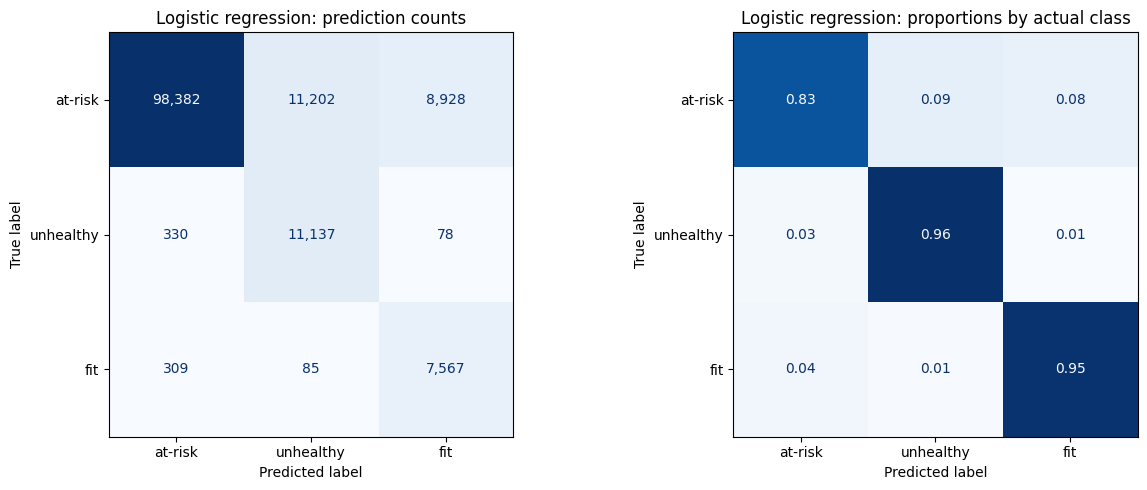

In [18]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay.from_predictions(
    y_valid,
    logistic_predictions,
    labels=class_order,
    display_labels=class_order,
    cmap="Blues",
    values_format=",d",
    colorbar=False,
    ax=axes[0]
)

axes[0].set_title("Logistic regression: prediction counts")

ConfusionMatrixDisplay.from_predictions(
    y_valid,
    logistic_predictions,
    labels=class_order,
    display_labels=class_order,
    normalize="true",
    cmap="Blues",
    values_format=".2f",
    colorbar=False,
    ax=axes[1]
)

axes[1].set_title("Logistic regression: proportions by actual class")

plt.tight_layout()
plt.show()

In [19]:
from sklearn.ensemble import RandomForestClassifier

forest_numeric_preprocessing = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="median",
            add_indicator=True
        )
    )
])

forest_categorical_preprocessing = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="constant",
            fill_value="missing"
        )
    ),
    (
        "encoder",
        OneHotEncoder(handle_unknown="ignore")
    )
])

forest_preprocessor = ColumnTransformer([
    (
        "numeric",
        forest_numeric_preprocessing,
        numeric_columns
    ),
    (
        "categorical",
        forest_categorical_preprocessing,
        categorical_columns
    )
])

forest_model = Pipeline([
    ("preprocessing", forest_preprocessor),
    (
        "classifier",
        RandomForestClassifier(
            n_estimators=150,
            max_depth=18,
            min_samples_leaf=10,
            class_weight="balanced",
            n_jobs=-1,
            random_state=RANDOM_STATE
        )
    )
])

print("Random forest pipeline created.")

Random forest pipeline created.


In [20]:
start_time = time.perf_counter()

forest_model.fit(X_train, y_train)
forest_predictions = forest_model.predict(X_valid)

forest_elapsed = time.perf_counter() - start_time

forest_result = {
    "model": "Balanced random forest",
    "accuracy": accuracy_score(
        y_valid,
        forest_predictions
    ),
    "balanced_accuracy": balanced_accuracy_score(
        y_valid,
        forest_predictions
    )
}

results = [
    result for result in results
    if result["model"] != forest_result["model"]
]
results.append(forest_result)

display(
    pd.DataFrame(results)
    .sort_values("balanced_accuracy", ascending=False)
    .round(4)
)

print(
    f"\nRandom forest training and prediction time: "
    f"{forest_elapsed:.1f} seconds"
)

print("\nPerformance by health category:")
print(
    classification_report(
        y_valid,
        forest_predictions,
        labels=class_order,
        digits=4,
        zero_division=0
    )
)

,model,accuracy,balanced_accuracy
2,Balanced random forest,0.9466,0.9472
1,Balanced logistic regression,0.8483,0.9151
0,Most frequent class baseline,0.8587,0.3333



Random forest training and prediction time: 160.9 seconds

Performance by health category:
              precision    recall  f1-score   support

     at-risk     0.9918    0.9464    0.9686    118512
   unhealthy     0.7365    0.9487    0.8293     11545
         fit     0.7486    0.9465    0.8360      7961

    accuracy                         0.9466    138018
   macro avg     0.8257    0.9472    0.8780    138018
weighted avg     0.9565    0.9466    0.9493    138018



## Random forest results

The balanced random forest achieved 94.66% accuracy and 94.72%
balanced accuracy on the same validation split used for logistic
regression. Balanced accuracy improved by 3.21 percentage points.

Recall was similar across the three categories: 94.64% for at-risk,
94.87% for unhealthy and 94.65% for fit. Precision for unhealthy and
fit also improved substantially compared with logistic regression,
indicating fewer false positive predictions.

Training and prediction took 177.9 seconds. The random forest is the
best-performing model so far, although additional models and feature
experiments are still needed before final selection.

In [21]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import OrdinalEncoder

boosting_preprocessor = ColumnTransformer([
    (
        "numeric",
        "passthrough",
        numeric_columns
    ),
    (
        "categorical",
        Pipeline([
            (
                "imputer",
                SimpleImputer(
                    strategy="constant",
                    fill_value="missing"
                )
            ),
            (
                "encoder",
                OrdinalEncoder(
                    handle_unknown="use_encoded_value",
                    unknown_value=-1
                )
            )
        ]),
        categorical_columns
    )
])

# ColumnTransformer outputs numeric columns first,
# followed by the categorical columns.
categorical_mask = (
    [False] * len(numeric_columns)
    + [True] * len(categorical_columns)
)

boosting_model = Pipeline([
    ("preprocessing", boosting_preprocessor),
    (
        "classifier",
        HistGradientBoostingClassifier(
            categorical_features=categorical_mask,
            class_weight="balanced",
            learning_rate=0.1,
            max_iter=200,
            max_leaf_nodes=31,
            l2_regularization=1.0,
            early_stopping=False,
            random_state=RANDOM_STATE
        )
    )
])

print("Gradient boosting pipeline created.")

Gradient boosting pipeline created.


In [22]:
start_time = time.perf_counter()

boosting_model.fit(X_train, y_train)
boosting_predictions = boosting_model.predict(X_valid)

boosting_elapsed = time.perf_counter() - start_time

boosting_result = {
    "model": "Balanced histogram gradient boosting",
    "accuracy": accuracy_score(
        y_valid,
        boosting_predictions
    ),
    "balanced_accuracy": balanced_accuracy_score(
        y_valid,
        boosting_predictions
    )
}

results = [
    result for result in results
    if result["model"] != boosting_result["model"]
]
results.append(boosting_result)

comparison_table = (
    pd.DataFrame(results)
    .sort_values("balanced_accuracy", ascending=False)
    .reset_index(drop=True)
)

display(comparison_table.round(4))

print(
    f"\nGradient boosting training and prediction time: "
    f"{boosting_elapsed:.1f} seconds"
)

print("\nPerformance by health category:")
print(
    classification_report(
        y_valid,
        boosting_predictions,
        labels=class_order,
        digits=4,
        zero_division=0
    )
)

,model,accuracy,balanced_accuracy
0,Balanced histogram gradient boosting,0.9401,0.9500
1,Balanced random forest,0.9466,0.9472
2,Balanced logistic regression,0.8483,0.9151
3,Most frequent class baseline,0.8587,0.3333



Gradient boosting training and prediction time: 43.0 seconds

Performance by health category:
              precision    recall  f1-score   support

     at-risk     0.9935    0.9372    0.9645    118512
   unhealthy     0.6949    0.9643    0.8077     11545
         fit     0.7399    0.9484    0.8313      7961

    accuracy                         0.9401    138018
   macro avg     0.8094    0.9500    0.8678    138018
weighted avg     0.9539    0.9401    0.9437    138018



## Gradient boosting results

Histogram gradient boosting achieved 94.01% accuracy and 95.00%
balanced accuracy. This was the highest balanced accuracy among
the models tested, exceeding random forest by approximately
0.28 percentage points.

Recall was 93.72% for at-risk, 96.43% for unhealthy and 94.84%
for fit. Training and prediction took 57.2 seconds, compared
with 177.9 seconds for random forest.

Gradient boosting is the provisional preferred model because
it achieved the highest competition metric with a shorter
runtime in these experiments. Its advantage is small and
requires further assessment.

In [23]:
from sklearn.preprocessing import FunctionTransformer

def add_engineered_features(X):
    """Create features using only information in each record."""
    X_new = X.copy()

    X_new["sleep_duration_squared"] = (
        X_new["sleep_duration"] ** 2
    )

    X_new["steps_exercise_interaction"] = (
        X_new["step_count"] * X_new["exercise_duration"]
    )

    return X_new

feature_builder = FunctionTransformer(
    add_engineered_features,
    validate=False
)

# Preview the calculations without changing X_train.
preview = feature_builder.transform(X_train.head())

display(
    preview[[
        "sleep_duration",
        "sleep_duration_squared",
        "step_count",
        "exercise_duration",
        "steps_exercise_interaction"
    ]]
)

,sleep_duration,sleep_duration_squared,step_count,exercise_duration,steps_exercise_interaction
313415,7.17,51.4089,1398.0,49.1,68641.8
3515,NaN,NaN,13466.0,50.8,684072.8
501194,8.66,74.9956,9473.0,23.3,220720.9
303602,NaN,NaN,7052.0,21.6,152323.2
117943,8.83,77.9689,13521.0,52.9,715260.9


In [24]:
from sklearn.base import clone

feature_experiments = {
    "Boosting + sleep squared": [
        "sleep_duration_squared"
    ],
    "Boosting + activity interaction": [
        "steps_exercise_interaction"
    ],
    "Boosting + both features": [
        "sleep_duration_squared",
        "steps_exercise_interaction"
    ]
}

feature_results = [{
    "experiment": "Boosting: original features",
    "balanced_accuracy": boosting_result["balanced_accuracy"],
    "change_from_original": 0.0
}]

feature_models = {}

for experiment_name, added_columns in feature_experiments.items():
    experiment_numeric_columns = (
        numeric_columns + added_columns
    )

    experiment_preprocessor = ColumnTransformer([
        (
            "numeric",
            "passthrough",
            experiment_numeric_columns
        ),
        (
            "categorical",
            clone(
                boosting_preprocessor
                .named_transformers_["categorical"]
            ),
            categorical_columns
        )
    ])

    experiment_mask = (
        [False] * len(experiment_numeric_columns)
        + [True] * len(categorical_columns)
    )

    experiment_classifier = clone(
        boosting_model.named_steps["classifier"]
    ).set_params(
        categorical_features=experiment_mask
    )

    experiment_model = Pipeline([
        (
            "feature_engineering",
            FunctionTransformer(
                add_engineered_features,
                validate=False
            )
        ),
        ("preprocessing", experiment_preprocessor),
        ("classifier", experiment_classifier)
    ])

    experiment_model.fit(X_train, y_train)
    predictions = experiment_model.predict(X_valid)

    score = balanced_accuracy_score(
        y_valid,
        predictions
    )

    feature_models[experiment_name] = experiment_model

    feature_results.append({
        "experiment": experiment_name,
        "balanced_accuracy": score,
        "change_from_original": (
            score - boosting_result["balanced_accuracy"]
        )
    })

    print(f"{experiment_name}: {score:.6f}")

feature_comparison = pd.DataFrame(feature_results)

display(
    feature_comparison
    .sort_values("balanced_accuracy", ascending=False)
    .reset_index(drop=True)
    .round(6)
)

Boosting + sleep squared: 0.949958
Boosting + activity interaction: 0.949827
Boosting + both features: 0.949827


,experiment,balanced_accuracy,change_from_original
0,Boosting: original features,0.949958,0.000000
1,Boosting + sleep squared,0.949958,0.000000
2,Boosting + activity interaction,0.949827,-0.000131
3,Boosting + both features,0.949827,-0.000131


## Feature engineering experiments

Two features were created: squared sleep duration and an interaction
between step count and exercise duration. Each was tested separately
and together using the same validation split and gradient boosting
settings.

Squared sleep duration left balanced accuracy unchanged at 0.949958.
The activity interaction, alone or with squared sleep duration,
produced a slightly lower score of 0.949827.

Neither feature improved validation performance. Therefore, the
original feature set was retained for subsequent model tuning.

In [25]:
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold
)
from sklearn.base import clone

# Take a reproducible, stratified subset from training data only.
if len(X_train) > 120_000:
    X_tune, _, y_tune, _ = train_test_split(
        X_train,
        y_train,
        train_size=120_000,
        stratify=y_train,
        random_state=RANDOM_STATE
    )
else:
    X_tune = X_train.copy()
    y_tune = y_train.copy()

parameter_grid = {
    "classifier__max_leaf_nodes": [15, 31, 63],
    "classifier__l2_regularization": [1.0, 10.0]
}

cv_scheme = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE
)

search = GridSearchCV(
    estimator=clone(boosting_model),
    param_grid=parameter_grid,
    scoring="balanced_accuracy",
    cv=cv_scheme,
    n_jobs=1,
    refit=False,
    return_train_score=False,
    verbose=1
)

print("Records used for tuning:", len(X_tune))
print("Parameter combinations: 6")
print("Cross-validation fits: 18")

start_time = time.perf_counter()

search.fit(X_tune, y_tune)

print(
    f"\nSearch time: "
    f"{time.perf_counter() - start_time:.1f} seconds"
)

print("\nBest settings:")
print(search.best_params_)

print(
    "\nBest mean cross-validation balanced accuracy:",
    round(search.best_score_, 6)
)

Records used for tuning: 120000
Parameter combinations: 6
Cross-validation fits: 18
Fitting 3 folds for each of 6 candidates, totalling 18 fits

Search time: 197.0 seconds

Best settings:
{'classifier__l2_regularization': 10.0, 'classifier__max_leaf_nodes': 15}

Best mean cross-validation balanced accuracy: 0.947567


In [26]:
tuning_results = pd.DataFrame(search.cv_results_)

tuning_table = tuning_results[[
    "param_classifier__max_leaf_nodes",
    "param_classifier__l2_regularization",
    "mean_test_score",
    "std_test_score",
    "rank_test_score"
]].rename(columns={
    "param_classifier__max_leaf_nodes": "max_leaf_nodes",
    "param_classifier__l2_regularization": "l2_regularization",
    "mean_test_score": "mean_cv_balanced_accuracy",
    "std_test_score": "cv_score_std",
    "rank_test_score": "rank"
})

display(
    tuning_table
    .sort_values("rank")
    .reset_index(drop=True)
    .round(6)
)

,max_leaf_nodes,l2_regularization,mean_cv_balanced_accuracy,cv_score_std,rank
0,15,10.0,0.947567,0.001453,1
1,15,1.0,0.946557,0.001837,2
2,31,10.0,0.941969,0.002580,3
3,31,1.0,0.936533,0.003666,4
4,63,10.0,0.929155,0.003521,5
5,63,1.0,0.917862,0.002572,6


In [27]:
tuned_boosting_model = clone(boosting_model).set_params(
    **search.best_params_
)

start_time = time.perf_counter()

tuned_boosting_model.fit(X_train, y_train)

tuned_predictions = tuned_boosting_model.predict(X_valid)

tuned_result = {
    "model": "CV-tuned histogram gradient boosting",
    "accuracy": accuracy_score(
        y_valid,
        tuned_predictions
    ),
    "balanced_accuracy": balanced_accuracy_score(
        y_valid,
        tuned_predictions
    )
}

results = [
    result for result in results
    if result["model"] != tuned_result["model"]
]
results.append(tuned_result)

display(
    pd.DataFrame(results)
    .sort_values("balanced_accuracy", ascending=False)
    .reset_index(drop=True)
    .round(6)
)

print(
    f"\nTraining and prediction time: "
    f"{time.perf_counter() - start_time:.1f} seconds"
)

print("\nPerformance by health category:")
print(
    classification_report(
        y_valid,
        tuned_predictions,
        labels=class_order,
        digits=4,
        zero_division=0
    )
)

,model,accuracy,balanced_accuracy
0,Balanced histogram gradient boosting,0.940102,0.949958
1,CV-tuned histogram gradient boosting,0.938349,0.949929
2,Balanced random forest,0.946594,0.947202
3,Balanced logistic regression,0.848339,0.915104
4,Most frequent class baseline,0.858671,0.333333



Training and prediction time: 40.4 seconds

Performance by health category:
              precision    recall  f1-score   support

     at-risk     0.9937    0.9350    0.9634    118512
   unhealthy     0.6885    0.9657    0.8039     11545
         fit     0.7325    0.9491    0.8269      7961

    accuracy                         0.9383    138018
   macro avg     0.8049    0.9499    0.8647    138018
weighted avg     0.9531    0.9383    0.9422    138018



## Hyperparameter tuning and model choice

A grid search compared six combinations of maximum leaf nodes and
L2 regularisation using three-fold stratified cross-validation on
a 120,000-record subset of the training portion.

The selected settings were then fitted on the full training portion.
They achieved 0.949929 balanced accuracy on validation, compared with
0.949958 for the original gradient boosting model.

The difference was negligible, and tuning did not improve validation
performance. The original gradient boosting pipeline with the original
features was therefore selected for the Kaggle submission.

This choice is based on development validation results. Because the
same validation set has been used for several comparisons, its score
should not be treated as a completely independent final assessment.

In [28]:
from pathlib import Path

output_folder = Path("/content/student_health_outputs")
output_folder.mkdir(parents=True, exist_ok=True)

model_comparison = (
    pd.DataFrame(results)
    .sort_values("balanced_accuracy", ascending=False)
    .reset_index(drop=True)
)

model_comparison.to_csv(
    output_folder / "model_comparison.csv",
    index=False
)

feature_comparison.to_csv(
    output_folder / "feature_experiments.csv",
    index=False
)

tuning_table.to_csv(
    output_folder / "hyperparameter_search.csv",
    index=False
)

print("Best cross-validation settings:")
print(search.best_params_)

print("\nExperiment tables saved.")

Best cross-validation settings:
{'classifier__l2_regularization': 10.0, 'classifier__max_leaf_nodes': 15}

Experiment tables saved.


In [29]:
from sklearn.base import clone

# Copy the original gradient boosting pipeline and its settings.
final_model = clone(boosting_model)

start_time = time.perf_counter()

final_model.fit(X, y)

test_predictions = final_model.predict(
    test[predictor_columns]
)

print(
    f"Final training and prediction time: "
    f"{time.perf_counter() - start_time:.1f} seconds"
)

print("Number of predictions:", len(test_predictions))

Final training and prediction time: 58.8 seconds
Number of predictions: 295753


In [30]:
submission = sample_submission.copy()
submission[target] = test_predictions

# Check the required structure and row alignment.
assert submission.columns.tolist() == [
    "id", "health_condition"
]
assert len(submission) == len(test)
assert submission["id"].equals(test["id"])
assert submission["id"].is_unique
assert submission[target].notna().all()
assert set(submission[target]).issubset(set(y.unique()))

submission_path = output_folder / "submission.csv"

submission.to_csv(submission_path, index=False)

display(submission.head())

print("\nPredicted category distribution:")
display(
    submission[target]
    .value_counts()
    .rename("count")
    .to_frame()
)

print("\nSubmission checks passed.")

,id,health_condition
0,690088,unhealthy
1,690089,unhealthy
2,690090,at-risk
3,690091,at-risk
4,690092,unhealthy



Predicted category distribution:


,count
health_condition,
at-risk,240060
unhealthy,33958
fit,21735



Submission checks passed.


In [31]:
import shutil
from google.colab import files

# Download the file to upload to Kaggle.
files.download(str(submission_path))

# Download a backup containing the submission and result tables.
backup_path = shutil.make_archive(
    "/content/student_health_results",
    "zip",
    root_dir=output_folder
)

files.download(backup_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [32]:
from sklearn.base import clone
from google.colab import files

# Retrain random forest on all labelled records.
final_forest = clone(forest_model)
final_forest.fit(X, y)

# Predict the competition test records.
forest_submission = sample_submission.copy()
forest_submission[target] = final_forest.predict(
    test[predictor_columns]
)

# Check and save the submission.
assert forest_submission["id"].equals(test["id"])
assert forest_submission[target].notna().all()
assert set(forest_submission[target]).issubset(set(y.unique()))

forest_submission.to_csv(
    "/content/submission_random_forest.csv",
    index=False
)

files.download("/content/submission_random_forest.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>